**APPLICATION OF RESIDUAL NETWORK MODEL (ResNet)**

In [3]:
import zipfile

zip_path = "/content/Cotton__Disease.zip"   # uploaded file
extract_path = "/content/dataset"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted!")


Dataset extracted!


In [2]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.layers import Dense, Flatten, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.applications.resnet50 import ResNet50
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
import os
from tensorflow.keras.applications.resnet50 import ResNet50, preprocess_input

# Define paths
train_path = "/content/dataset/Cotton Disease/train"
test_path = "/content/dataset/Cotton Disease/test"
val_path =  "/content/dataset/Cotton Disease/val"

# Image parameters
IMAGE_SIZE = [224, 224]
BATCH_SIZE = 32

# Data Augmentation needed for Training
# CRITICAL FIX: Use preprocess_input instead of rescale=1./255
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    rotation_range=20  # Added rotation for better augmentation
)

# Validation/Test should also use preprocess_input
test_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

# Training Set
train_set = train_datagen.flow_from_directory(
    train_path,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

# Validation Set
val_set = test_datagen.flow_from_directory(
    val_path,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

# Test Set
test_set = test_datagen.flow_from_directory(
    test_path,
    target_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)


Found 1951 images belonging to 4 classes.
Found 253 images belonging to 4 classes.
Found 106 images belonging to 4 classes.


In [5]:
# Load ResNet50
resnet = ResNet50(input_shape=IMAGE_SIZE + [3], weights='imagenet', include_top=False)

# Don't train existing weights
for layer in resnet.layers:
    layer.trainable = False

x = GlobalAveragePooling2D()(resnet.output)
# Simplified Head: 256 units helps prevent overfitting on smaller datasets
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)
prediction = Dense(4, activation='softmax')(x)

# Create Model
model = Model(inputs=resnet.input, outputs=prediction)

model.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

In [3]:


model.summary()

# Callbacks
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True, verbose=1)
checkpoint = ModelCheckpoint('model_resnet.h5', monitor='val_accuracy', save_best_only=True, verbose=1)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, verbose=1)

# Train Phase 1: Feature Extraction (Head only)
print("Phase 1: Training Classification Head...")
history_1 = model.fit(
    train_set,
    validation_data=val_set,
    epochs=10,  # Train head for fewer epochs first
    steps_per_epoch=len(train_set),
    validation_steps=len(val_set),
    callbacks=[early_stop, checkpoint, reduce_lr]
)


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 24,113,284 (91.98 MB)

 Trainable params: 525,572 (2.00 MB)

...

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/10
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.6258 - loss: 1.1250
Epoch 1: val_accuracy improved from -inf to 0.91304, saving model to model_resnet.h5


61/61 ━━━━━━━━━━━━━━━━━━━━ 445s 7s/step - accuracy: 0.6277 - loss: 1.1181 - val_accuracy: 0.9130 - val_loss: 0.2637 - learning_rate: 0.0010
Epoch 2/10
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.8749 - loss: 0.3254
Epoch 2: val_accuracy improved from 0.91304 to 0.96047, saving model to model_resnet.h5


61/61 ━━━━━━━━━━━━━━━━━━━━ 419s 7s/step - accuracy: 0.8751 - loss: 0.3253 - val_accuracy: 0.9605 - val_loss: 0.1416 - learning_rate: 0.0010
Epoch 3/10
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.9130 - loss: 0.2591
Epoch 3: val_accuracy did not improve from 0.96047
61/61 ━━━━━━━━━━━━━━━━━━━━ 414s 7s/step - accuracy: 0.9130 - loss: 0.2590 - val_accuracy: 0.9565 - val_loss: 0.1314 - learning_rate: 0.0010
Epoch 4/10
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.8926 - loss: 0.2538
Epoch 4: val_accuracy did not improve from 0.96047
61/61 ━━━━━━━━━━━━━━━━━━━━ 413s 7s/step - accuracy: 0.8928 - loss: 0.2534 - val_accuracy: 0.9526 - val_loss: 0.1236 - learning_rate: 0.0010
Epoch 5/10
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.9131 - loss: 0.2205
Epoch 5: val_accuracy did not improve from 0.96047
61/61 ━━━━━━━━━━━━━━━━━━━━ 412s 7s/step - accuracy: 0.9132 - loss: 0.2204 - val_accuracy: 0.9565 - val_loss: 0.1558 - learning_rate: 0.0010
Epoch 6/10
61/61 ━━━━━━━━━━━━━━━━━━━━ 

61/61 ━━━━━━━━━━━━━━━━━━━━ 418s 7s/step - accuracy: 0.9413 - loss: 0.1547 - val_accuracy: 0.9684 - val_loss: 0.0858 - learning_rate: 0.0010
Epoch 10/10
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.9556 - loss: 0.1407
Epoch 10: val_accuracy did not improve from 0.96838
61/61 ━━━━━━━━━━━━━━━━━━━━ 436s 7s/step - accuracy: 0.9555 - loss: 0.1409 - val_accuracy: 0.9565 - val_loss: 0.0925 - learning_rate: 0.0010
Restoring model weights from the end of the best epoch: 8.


In [4]:
# Phase 2: Fine-Tuning
print("Phase 2: Fine-Tuning ResNet Base...")
resnet.trainable = True

# Fine-tune starting from the last 50 layers
for layer in resnet.layers[:-50]:
    layer.trainable = False

# Recompile with a low learning rate
model.compile(
    loss='categorical_crossentropy',
    optimizer=tf.keras.optimizers.Adam(1e-5),  # Low learning rate is critical
    metrics=['accuracy']
)

# Callbacks for fine-tuning
checkpoint_ft = ModelCheckpoint('model_resnet_finetuned.h5', monitor='val_accuracy', save_best_only=True, verbose=1)
early_stop_ft = EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True, verbose=1)
reduce_lr_ft = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, verbose=1)

history_2 = model.fit(
    train_set,
    validation_data=val_set,
    epochs=30,  # Train longer for fine-tuning
    initial_epoch=history_1.epoch[-1],
    steps_per_epoch=len(train_set),
    validation_steps=len(val_set),
    callbacks=[early_stop_ft, checkpoint_ft, reduce_lr_ft]
)

Phase 2: Fine-Tuning ResNet Base...
Epoch 10/30
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.9572 - loss: 0.1238
Epoch 10: val_accuracy improved from -inf to 0.96443, saving model to model_resnet_finetuned.h5


61/61 ━━━━━━━━━━━━━━━━━━━━ 425s 7s/step - accuracy: 0.9572 - loss: 0.1238 - val_accuracy: 0.9644 - val_loss: 0.0792 - learning_rate: 1.0000e-05
Epoch 11/30
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.9582 - loss: 0.1271
Epoch 11: val_accuracy improved from 0.96443 to 0.96838, saving model to model_resnet_finetuned.h5


61/61 ━━━━━━━━━━━━━━━━━━━━ 439s 7s/step - accuracy: 0.9582 - loss: 0.1270 - val_accuracy: 0.9684 - val_loss: 0.0812 - learning_rate: 1.0000e-05
Epoch 12/30
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.9476 - loss: 0.1273
Epoch 12: val_accuracy did not improve from 0.96838
61/61 ━━━━━━━━━━━━━━━━━━━━ 440s 7s/step - accuracy: 0.9476 - loss: 0.1273 - val_accuracy: 0.9644 - val_loss: 0.0833 - learning_rate: 1.0000e-05
Epoch 13/30
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.9586 - loss: 0.1088
Epoch 13: val_accuracy did not improve from 0.96838

Epoch 13: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-06.
61/61 ━━━━━━━━━━━━━━━━━━━━ 443s 7s/step - accuracy: 0.9586 - loss: 0.1089 - val_accuracy: 0.9684 - val_loss: 0.0827 - learning_rate: 1.0000e-05
Epoch 14/30
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 6s/step - accuracy: 0.9555 - loss: 0.1233
Epoch 14: val_accuracy did not improve from 0.96838
61/61 ━━━━━━━━━━━━━━━━━━━━ 412s 7s/step - accuracy: 0.9556 - loss: 0.1232 - val_ac

In [5]:
val_losses = history_2.history['val_loss']
best_epoch = np.argmin(val_losses) + 1   # +1 because epochs are 1-indexed

train_acc = history_2.history['accuracy'][best_epoch - 1]
val_acc   = history_2.history['val_accuracy'][best_epoch - 1]
best_val_loss = val_losses[best_epoch - 1]

print(f"Best epoch: {best_epoch}")
print(f"Training accuracy: {train_acc:.4f}")
print(f"Validation loss: {best_val_loss:.4f}")
print(f"Validation accuracy: {val_acc:.4f}")

Best epoch: 1
Training accuracy: 0.9590
Validation loss: 0.0792
Validation accuracy: 0.9644


In [6]:


# Evaluate on Test Set
print("Evaluating on Test Set...")
test_loss, test_accuracy = model.evaluate(test_set)
print(f"Test Accuracy: {test_accuracy}")

Evaluating on Test Set...
4/4 ━━━━━━━━━━━━━━━━━━━━ 21s 5s/step - accuracy: 0.9703 - loss: 0.0899
Test Accuracy: 0.9622641801834106


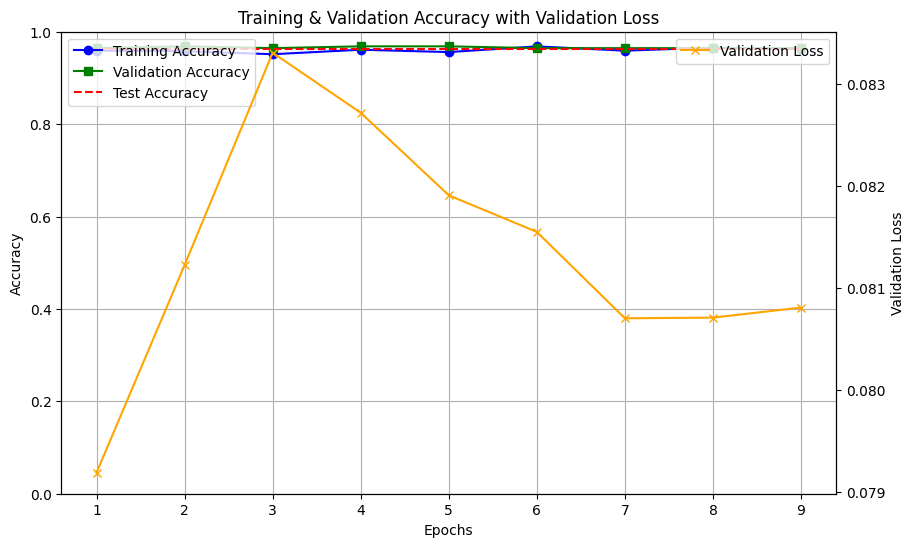

In [7]:
import matplotlib.pyplot as plt

# 1️⃣ Get metrics from history
train_acc = history_2.history['accuracy']
val_acc = history_2.history['val_accuracy']
val_loss = history_2.history['val_loss']

# Number of epochs actually run
epochs_ran = len(train_acc)
epochs = range(1, epochs_ran + 1)

# 2️⃣ Create figure and twin y-axis
fig, ax1 = plt.subplots(figsize=(10,6))

# Accuracy lines on left y-axis
ax1.plot(epochs, train_acc, label='Training Accuracy', marker='o', color='blue')
ax1.plot(epochs, val_acc, label='Validation Accuracy', marker='s', color='green')
ax1.hlines(test_accuracy, xmin=1, xmax=epochs_ran, colors='red', linestyles='dashed', label='Test Accuracy')

ax1.set_xlabel('Epochs')
ax1.set_ylabel('Accuracy')
ax1.set_ylim(0, 1)
ax1.legend(loc='upper left')

# Loss line on right y-axis
ax2 = ax1.twinx()
ax2.plot(epochs, val_loss, label='Validation Loss', marker='x', color='orange')
ax2.set_ylabel('Validation Loss')
ax2.legend(loc='upper right')

# Title and grid
plt.title('Training & Validation Accuracy with Validation Loss')
ax1.grid(True)

plt.show()


**APPLICATION OF LOCAL INTERPRETABLE MODEL-AGNOSTIC EXPLANATIONS (LIME)**

Loading test data...
Found 106 images belonging to 4 classes.
Searching for image #0 of class 'diseased cotton leaf'...
Found image! Explaining image with True Class: diseased cotton leaf
Generating LIME explanation (this may take a moment)...


  0%|          | 0/1000 [00:00<?, ?it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 

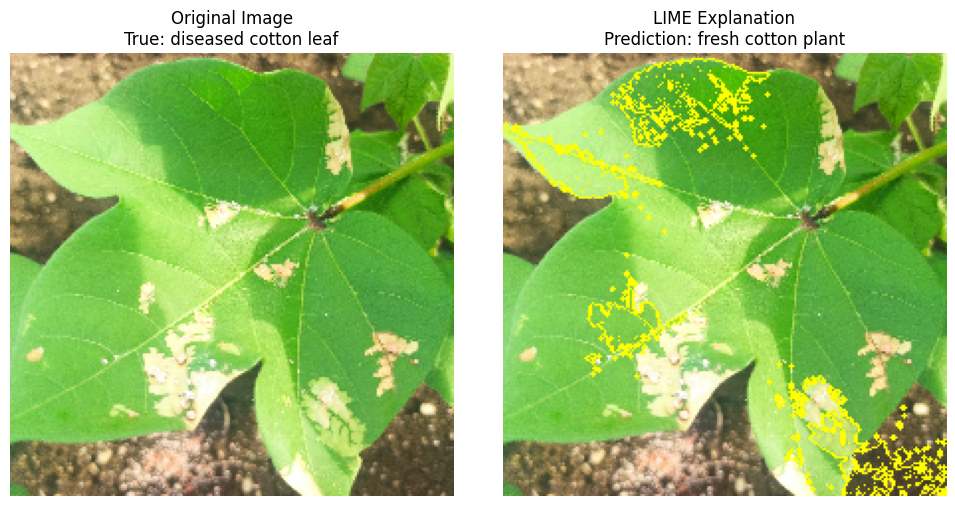

Explanation complete. Check the popup window for the plot.


In [7]:
!pip install lime
from lime import lime_image
from skimage.segmentation import mark_boundaries
import matplotlib.pyplot as plt
import numpy as np

# -----------------------------
# Configuration
# -----------------------------
MODEL_PATH = 'model_efficientnet_final_optimized.h5'
TEST_DIR = r"/content/dataset/Cotton Disease/test"
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# -----------------------------


# -----------------------------
# Data Loading (For Visualization)
# -----------------------------
# We use a 'raw' generator for LIME to get interpretable images (0-255)
# This allows LIME's segmentation to work on actual pixels, not normalized values.
print("Loading test data...")
test_datagen_raw = ImageDataGenerator() # No preprocessing here!

test_generator_raw = test_datagen_raw.flow_from_directory(
    TEST_DIR,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True # Shuffle to get random images
)

# -----------------------------
# Prediction Function (The Bridge)
# -----------------------------
def predict_fn(images):
    """
    LIME passes 'images' as a numpy array of shape (batch, h, w, c).
    These images are in the range of the input provided to LIME (likely 0-255).
    We must preprocess them exactly as the model expects before predicting.
    """
    # 1. Ensure images are float32
    images = np.array(images, dtype=np.float32)

    # 2. Apply EfficientNet preprocessing
    # preprocess_input operates in-place or returns copy.
    # It handles the scaling (-1 to 1 or 0 to 255 depending on version).
    processed_images = preprocess_input(images.copy())

    # 3. Predict
    return model.predict(processed_images)

# -----------------------------
# Select an Image (Configuration)
# -----------------------------
# Change these values to select a specific image
TARGET_CLASS_NAME = 'diseased cotton leaf' # Options: diseased cotton leaf, diseased cotton plant, fresh cotton leaf, fresh cotton plant
TARGET_INDEX = 0   #  for the 1st image of that class found, 1 for the 2nd, etc.

print(f"Searching for image #{TARGET_INDEX} of class '{TARGET_CLASS_NAME}'...")

# Get class indices mapping
label_map = (test_generator_raw.class_indices)
label_map_inv = {v: k for k, v in label_map.items()}

if TARGET_CLASS_NAME not in label_map:
    print(f"Error: Class '{TARGET_CLASS_NAME}' not found. Available classes: {list(label_map.keys())}")
    exit()

target_class_idx = label_map[TARGET_CLASS_NAME]

# Scan the generator to find the target image
img_to_explain = None
true_label_idx = None
count = 0
found = False

# Reset generator to be sure
test_generator_raw.reset()

max_batches = len(test_generator_raw)
for i in range(max_batches):
    batch_images, batch_labels = next(test_generator_raw)

    # Iterate through batch
    for j in range(len(batch_images)):
        current_label_idx = np.argmax(batch_labels[j])

        if current_label_idx == target_class_idx:
            if count == TARGET_INDEX:
                img_to_explain = batch_images[j]
                true_label_idx = current_label_idx
                found = True
                break
            count += 1

    if found:
        break

if not found:
    print(f"Error: Could not find image #{TARGET_INDEX} of class '{TARGET_CLASS_NAME}'. Found {count} images total.")
    exit()

print(f"Found image! Explaining image with True Class: {label_map_inv[true_label_idx]}")

# -----------------------------
# Run LIME
# -----------------------------
print("Generating LIME explanation (this may take a moment)...")
explainer = lime_image.LimeImageExplainer()

explanation = explainer.explain_instance(
    image=img_to_explain.astype('double'), # LIME likes double/float
    classifier_fn=predict_fn,
    top_labels=5,
    hide_color=0,
    num_samples=1000 # Increase for better quality, decrease for speed
)

# -----------------------------
# Get Explanation for Top Class
# -----------------------------
top_pred_class = explanation.top_labels[0]
print(f"Top Predicted Class: {label_map_inv[top_pred_class]}")

# Get image and mask for the top class
# positive_only=True shows only superpixels that contribute POSITIVELY to the class
temp, mask = explanation.get_image_and_mask(
    top_pred_class,
    positive_only=True,
    num_features=5,
    hide_rest=False
)

# -----------------------------
# Visualize
# -----------------------------
plt.figure(figsize=(10, 5))

# Original Image
plt.subplot(1, 2, 1)
plt.imshow(img_to_explain.astype('uint8'))
plt.title(f"Original Image\nTrue: {label_map_inv[true_label_idx]}")
plt.axis('off')

# LIME Explanation
plt.subplot(1, 2, 2)
plt.imshow(mark_boundaries(temp.astype('uint8'), mask))
plt.title(f"LIME Explanation\nPrediction: {label_map_inv[top_pred_class]}")
plt.axis('off')

plt.tight_layout()
plt.show()

print("Explanation complete. Check the popup window for the plot.")
